# Time Series Data Mining with tslearn and stumpy

This notebook explores time series classification, clustering, nearest-neighbor methods and Matrix Profile analysis.

**Libraries:** tslearn (classification, clustering, nearest neighbors), stumpy (Matrix Profile), NumPy, pandas, Matplotlib

**Datasets:**
- GunPoint and ECG200 from the UCR/UEA time series archive (http://timeseriesclassification.com/datasets)
- ECG Heartbeat Categorization Dataset (MIT-BIH) from Kaggle, used as my own data

**Contents**
1. Setup
2. Datasets
3. Classification and nearest neighbors
4. Clustering
5. tslearn and stumpy integration
6. Matrix Profile: motifs and anomalies
7. Own data: Kaggle ECG
8. Conclusions

## 1. Setup

In [ ]:
!pip install tslearn stumpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 8.0 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from tslearn.datasets import UCR_UEA_datasets
from tslearn.neighbors import KNeighborsTimeSeriesClassifier
from tslearn.clustering import TimeSeriesKMeans, KShape
from tslearn.svm import TimeSeriesSVC
from tslearn.preprocessing import TimeSeriesScalerMeanVariance
from tslearn.matrix_profile import MatrixProfile
from sklearn.metrics import accuracy_score, adjusted_rand_score

## 2. Datasets
Two benchmark datasets from the UCR/UEA archive. Both download automatically.

In [ ]:
datasets = {}
for name in ["GunPoint", "ECG200"]:
    Xtr, ytr, Xte, yte = UCR_UEA_datasets().load_dataset(name)
    datasets[name] = (Xtr, ytr, Xte, yte)
    print(name, "train:", Xtr.shape, "test:", Xte.shape, "classes:", np.unique(ytr))

GunPoint train: (50, 150, 1) test: (150, 150, 1) classes: [1 2]
ECG200 train: (100, 96, 1) test: (100, 96, 1) classes: [-1  1]


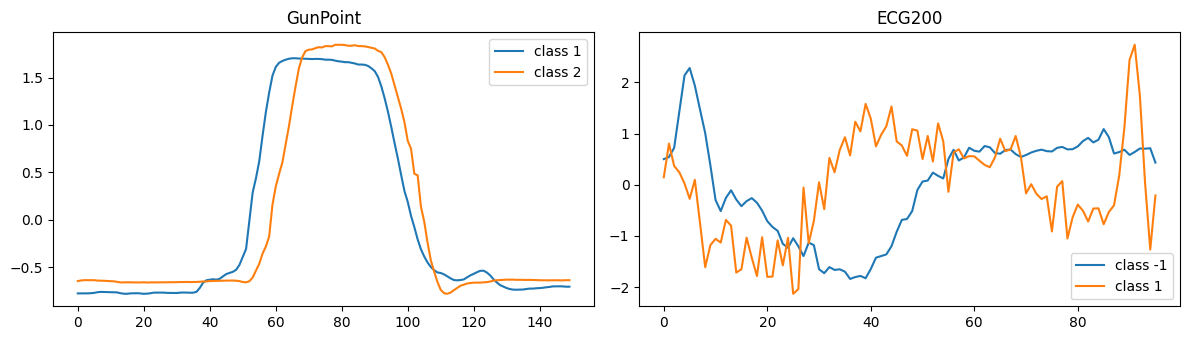

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, (Xtr, ytr, _, _)) in zip(axes, datasets.items()):
    for label in np.unique(ytr):
        ax.plot(Xtr[ytr == label][0].ravel(), label=f"class {label}")
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

**Observation:** _Describe how the classes differ visually in each dataset._

## 3. Classification and nearest neighbors
1-nearest-neighbor with Euclidean distance vs Dynamic Time Warping (DTW), plus a kernel SVM (Global Alignment Kernel).

In [ ]:
rows = []
for name, (Xtr, ytr, Xte, yte) in datasets.items():
    row = {"dataset": name}
    for metric in ["euclidean", "dtw"]:
        knn = KNeighborsTimeSeriesClassifier(n_neighbors=1, metric=metric).fit(Xtr, ytr)
        row[f"1NN-{metric}"] = round(accuracy_score(yte, knn.predict(Xte)), 3)
    svc = TimeSeriesSVC(kernel="gak").fit(Xtr, ytr)
    row["SVC-GAK"] = round(accuracy_score(yte, svc.predict(Xte)), 3)
    rows.append(row)
class_results = pd.DataFrame(rows)
class_results

,dataset,1NN-euclidean,1NN-dtw,SVC-GAK
0,GunPoint,0.913,0.907,0.767
1,ECG200,0.880,0.770,0.860


**Observation:** _Which method scored best on each dataset? Earlier runs gave GunPoint: Euclidean 0.913, DTW 0.907; ECG200: Euclidean 0.880, DTW 0.770. Explain why DTW did not help on ECG200 (the beats are already time-aligned, so flexible warping adds little and can match the wrong shapes)._

## 4. Clustering
k-means with DTW and k-Shape, scored against the true labels with the Adjusted Rand Index (1 = perfect, about 0 = random).

In [ ]:
rows = []
for name, (Xtr, ytr, _, _) in datasets.items():
    scaled = TimeSeriesScalerMeanVariance().fit_transform(Xtr)
    k = len(np.unique(ytr))
    km = TimeSeriesKMeans(n_clusters=k, metric="dtw", max_iter=10, random_state=0).fit(scaled)
    ks = KShape(n_clusters=k, random_state=0).fit(scaled)
    rows.append({"dataset": name,
                 "kmeans-DTW ARI": round(adjusted_rand_score(ytr, km.labels_), 3),
                 "KShape ARI": round(adjusted_rand_score(ytr, ks.labels_), 3)})
cluster_results = pd.DataFrame(rows)
cluster_results

,dataset,kmeans-DTW ARI,KShape ARI
0,GunPoint,-0.019,-0.019
1,ECG200,0.092,0.168


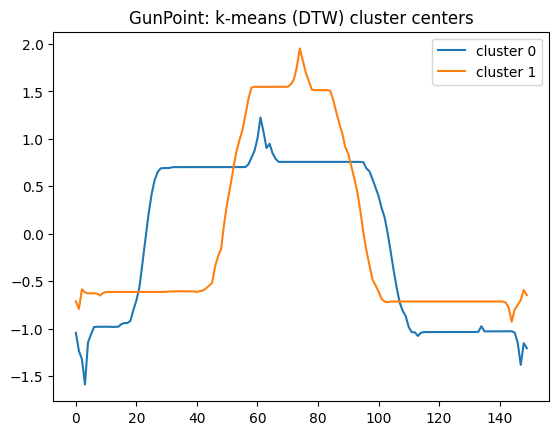

In [ ]:
Xtr, ytr, _, _ = datasets["GunPoint"]
scaled = TimeSeriesScalerMeanVariance().fit_transform(Xtr)
km = TimeSeriesKMeans(n_clusters=2, metric="dtw", max_iter=10, random_state=0).fit(scaled)
for i, c in enumerate(km.cluster_centers_):
    plt.plot(c.ravel(), label=f"cluster {i}")
plt.legend(); plt.title("GunPoint: k-means (DTW) cluster centers"); plt.show()

**Observation:** _Compare the ARI values. Clustering is unsupervised, so low scores mean the clusters found do not match the labeled classes. Say which method did better and what the cluster centers look like._

## 5. tslearn and stumpy integration
tslearn provides a `MatrixProfile` transformer that computes the matrix profile with stumpy as the backend, so it works directly on tslearn-format datasets.

Output shape: (6, 121, 1)


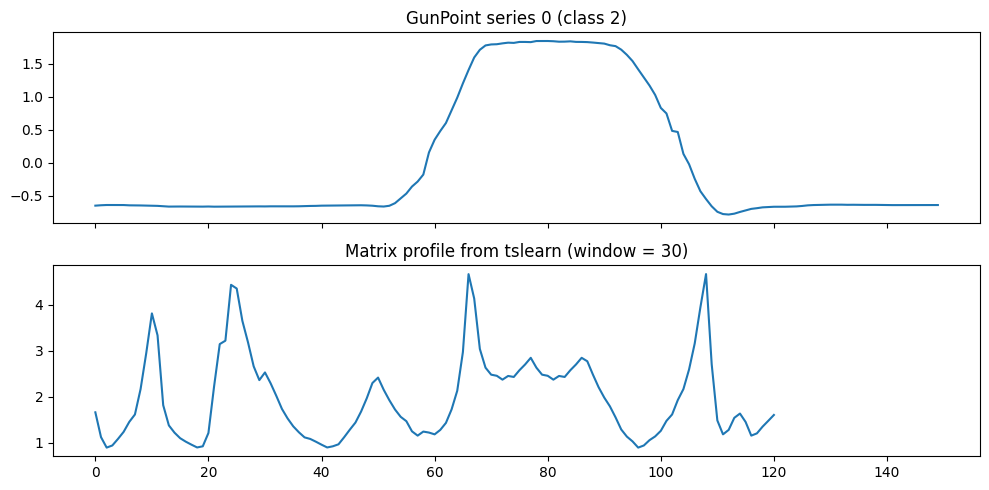

In [ ]:
Xtr, ytr, _, _ = datasets["GunPoint"]
mp_model = MatrixProfile(subsequence_length=30, scale=True)
mp_out = mp_model.fit_transform(Xtr[:6])
print("Output shape:", mp_out.shape)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(Xtr[0].ravel()); axes[0].set_title(f"GunPoint series 0 (class {ytr[0]})")
axes[1].plot(mp_out[0].ravel()); axes[1].set_title("Matrix profile from tslearn (window = 30)")
plt.tight_layout(); plt.show()

**Observation:** _Peaks in the profile mark the most unusual parts of the series; low values mark repeated patterns. Note that this class works on equal-length series in tslearn format._

## 6. Matrix Profile: motifs and anomalies
Using stumpy directly on ECG200. Ten heartbeats are joined into one long series. A motif is the closest repeated pair of subsequences (lowest profile value), and an anomaly (discord) is the subsequence least like any other (highest profile value).

Motif pair at 32 and 223 | Anomaly at 158


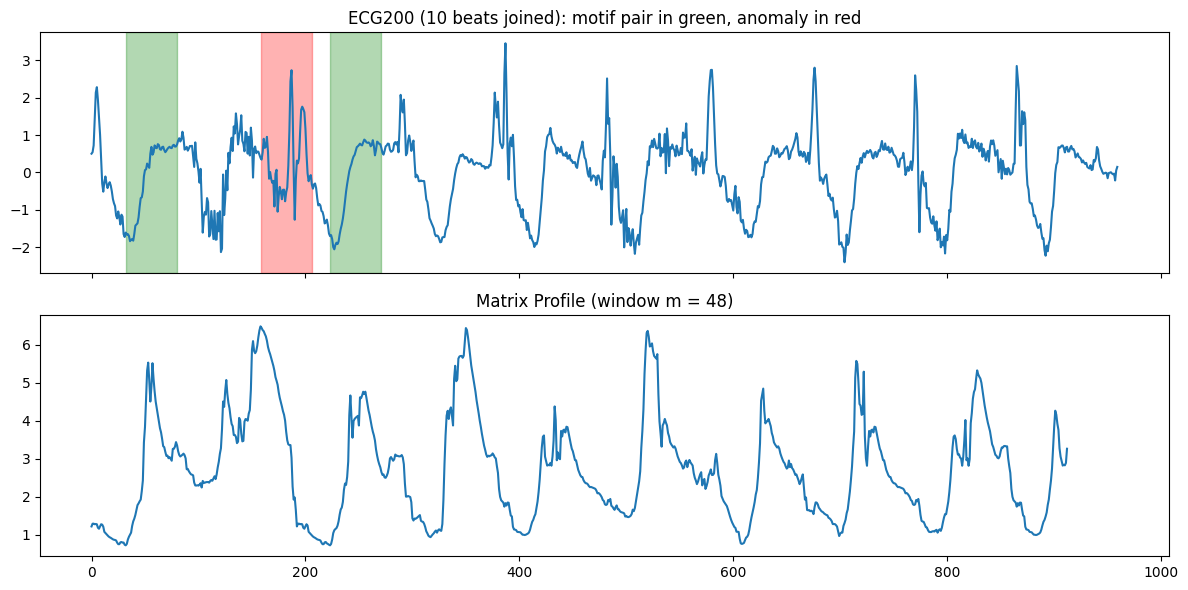

In [ ]:
Xtr, ytr, _, _ = datasets["ECG200"]
ts = np.concatenate([Xtr[i].ravel() for i in range(10)]).astype(float)
m = 48
mp = stumpy.stump(ts, m)
profile = mp[:, 0].astype(float)
motif = int(np.argmin(profile)); neighbor = int(mp[motif, 1])
anomaly = int(np.argmax(profile))
print("Motif pair at", motif, "and", neighbor, "| Anomaly at", anomaly)

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
ax[0].plot(ts)
for i, c in [(motif, "green"), (neighbor, "green"), (anomaly, "red")]:
    ax[0].axvspan(i, i + m, color=c, alpha=0.3)
ax[0].set_title("ECG200 (10 beats joined): motif pair in green, anomaly in red")
ax[1].plot(profile); ax[1].set_title(f"Matrix Profile (window m = {m})")
plt.tight_layout(); plt.show()

**Observation:** _Describe where the motif pair and the anomaly fall, and what part of the heartbeat they correspond to._

## 7. Own data: Kaggle ECG Heartbeat Categorization

Dataset: ECG Heartbeat Categorization Dataset (MIT-BIH) by Shayan Fazeli on Kaggle. Each row is one heartbeat of 187 values, and the last column is the class (0 = normal, 1 to 4 = abnormal types). The data files are not included in this repo. Download them from Kaggle and set `DATA_DIR` below.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Folder containing mitbih_train.csv and mitbih_test.csv
DATA_DIR = "/content"   # change to e.g. "/content/drive/MyDrive/ecg" if the files are on Drive
print(os.path.exists(f"{DATA_DIR}/mitbih_train.csv"), os.path.exists(f"{DATA_DIR}/mitbih_test.csv"))

Mounted at /content/drive
True True


In [ ]:
from sklearn.model_selection import train_test_split

data = pd.read_csv(f"{DATA_DIR}/mitbih_test.csv", header=None, dtype=np.float32)
print(data.shape)                              # expect (21892, 188)
print(data[187].value_counts().sort_index())   # expect all classes 0 to 4

def balanced_sample(df, n):
    return df.groupby(187, group_keys=False).apply(lambda g: g.sample(min(n, len(g)), random_state=0))

sub = balanced_sample(data, 100)
tr, te = train_test_split(sub, test_size=0.4, stratify=sub[187], random_state=0)
Xe_train = tr.iloc[:, :187].values[:, :, np.newaxis]
ye_train = tr.iloc[:, 187].values.astype(int)
Xe_test = te.iloc[:, :187].values[:, :, np.newaxis]
ye_test = te.iloc[:, 187].values.astype(int)
train = data   # the anomaly experiment below uses the variable `train`
print(Xe_train.shape, np.unique(ye_train, return_counts=True))

(21892, 188)
187
0.0    18118
1.0      556
2.0     1448
3.0      162
4.0     1608
Name: count, dtype: int64
(300, 187, 1) (array([0, 1, 2, 3, 4]), array([60, 60, 60, 60, 60]))


/tmp/ipykernel_586/2208683507.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby(187, group_keys=False).apply(lambda g: g.sample(min(n, len(g)), random_state=0))


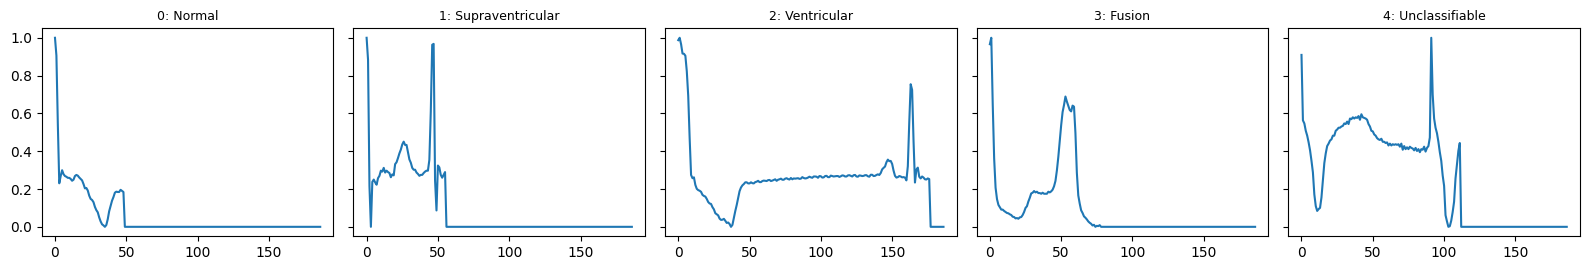

In [ ]:
names = {0: "Normal", 1: "Supraventricular", 2: "Ventricular", 3: "Fusion", 4: "Unclassifiable"}
fig, axes = plt.subplots(1, 5, figsize=(16, 2.8), sharey=True)
for c in range(5):
    axes[c].plot(Xe_train[ye_train == c][0].ravel())
    axes[c].set_title(f"{c}: {names[c]}", fontsize=9)
plt.tight_layout(); plt.show()

### 7.1 Classification and clustering on ECG

In [ ]:
row = {"dataset": "Kaggle ECG (subset)"}
for metric in ["euclidean", "dtw"]:
    knn = KNeighborsTimeSeriesClassifier(n_neighbors=1, metric=metric).fit(Xe_train, ye_train)
    row[f"1NN-{metric}"] = round(accuracy_score(ye_test, knn.predict(Xe_test)), 3)

scaled = TimeSeriesScalerMeanVariance().fit_transform(Xe_train)
km = TimeSeriesKMeans(n_clusters=5, metric="euclidean", random_state=0).fit(scaled)
row["kmeans ARI"] = round(adjusted_rand_score(ye_train, km.labels_), 3)
pd.DataFrame([row])

,dataset,1NN-euclidean,1NN-dtw,kmeans ARI
0,Kaggle ECG (subset),0.715,0.765,0.157


**Observation:** _Report accuracy for Euclidean vs DTW, and the clustering ARI. Five classes make this harder than the two-class benchmarks, so note whether accuracy dropped._

### 7.2 Anomaly detection with the Matrix Profile
Experiment: join 9 normal beats with 1 abnormal beat in the middle and check whether the Matrix Profile finds it without being told where it is.

Abnormal beat spans 935 to 1122 | Matrix Profile anomaly at 1387
Anomaly inside the abnormal beat: False


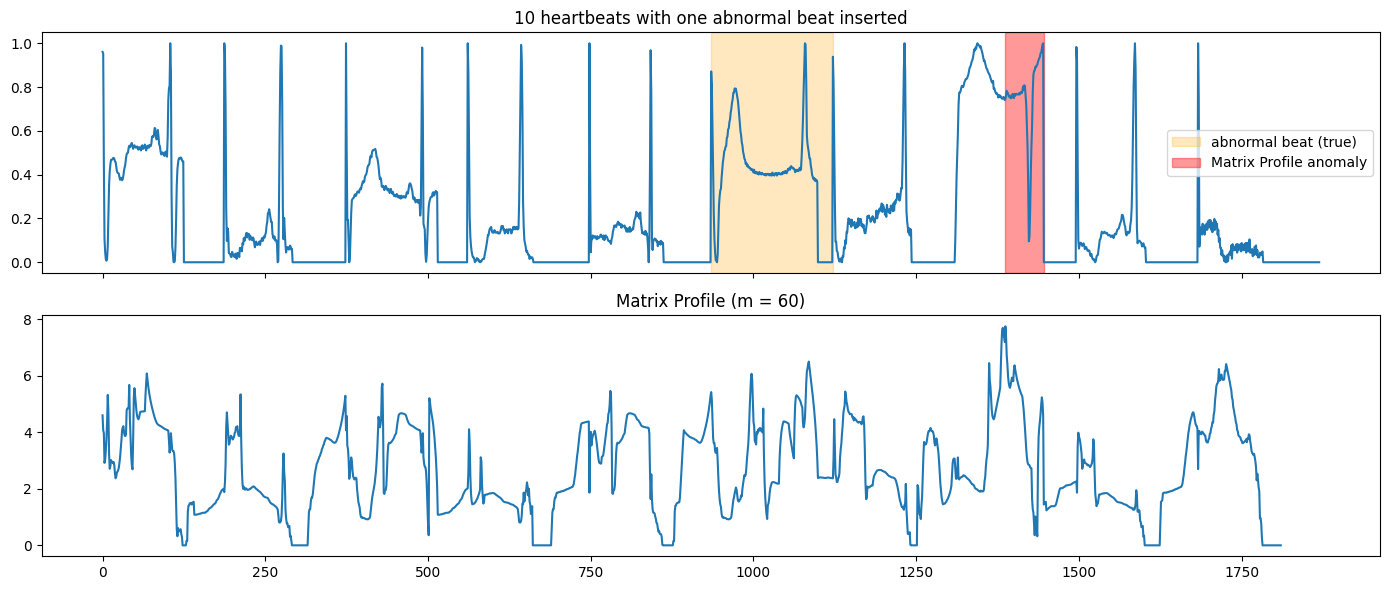

In [ ]:
normal = train[train[187] == 0].sample(9, random_state=1).iloc[:, :187].values
abnormal = train[train[187] == 2].sample(1, random_state=1).iloc[:, :187].values   # ventricular beat
beats = np.vstack([normal[:5], abnormal, normal[5:]])
ts2 = beats.ravel().astype(float)
true_start = 5 * 187

m = 60
mp2 = stumpy.stump(ts2, m)
prof2 = mp2[:, 0].astype(float)
found = int(np.argmax(prof2))
print("Abnormal beat spans", true_start, "to", true_start + 187, "| Matrix Profile anomaly at", found)
print("Anomaly inside the abnormal beat:", true_start - m <= found <= true_start + 187)

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(14, 6))
ax[0].plot(ts2)
ax[0].axvspan(true_start, true_start + 187, color="orange", alpha=0.25, label="abnormal beat (true)")
ax[0].axvspan(found, found + m, color="red", alpha=0.4, label="Matrix Profile anomaly")
ax[0].legend(); ax[0].set_title("10 heartbeats with one abnormal beat inserted")
ax[1].plot(prof2); ax[1].set_title(f"Matrix Profile (m = {m})")
plt.tight_layout(); plt.show()

In [24]:
normal_pool = train[train[187] == 0].iloc[:, :187].values
results = []
for cls in [1, 2, 3, 4]:
    abn_pool = train[train[187] == cls].iloc[:, :187].values
    for m in [30, 60, 100, 187]:
        hit = 0
        for seed in range(5):
            rng = np.random.default_rng(seed)
            normal = normal_pool[rng.choice(len(normal_pool), 9, replace=False)]
            abn = abn_pool[rng.integers(len(abn_pool))][None, :]
            ts_t = np.vstack([normal[:5], abn, normal[5:]]).ravel().astype(float)
            prof = stumpy.stump(ts_t, m)[:, 0].astype(float)
            found = int(np.argmax(prof))
            hit += (5 * 187 - m <= found <= 6 * 187)
        results.append({"abnormal class": cls, "window m": m, "detected (of 5)": hit})
pd.DataFrame(results).pivot(index="abnormal class", columns="window m", values="detected (of 5)")

window m,30,60,100,187
abnormal class,,,,
1,3,1,0,2
2,0,1,2,1
3,0,0,2,0
4,1,1,1,0


**Observation:** In the first run (window 60) the highest peak fell outside the inserted abnormal beat. Across 4 abnormal classes, 4 window sizes and 5 random draws each (80 runs), the Matrix Profile's top anomaly landed inside the abnormal beat 15 times (about 19%). It worked best for class 1 (6 of 20) and worst for class 3 (2 of 20), and no window size was clearly better. This is only slightly above what random guessing would give, so with this setup the Matrix Profile was not a reliable detector. A likely reason is that I joined only 9 normal beats, and normal heartbeats differ from one another, so many normal beats also have no close match and also produce high peaks. The Matrix Profile finds anomalies best when the normal pattern repeats many times.

## 8. Conclusions
- **Classification:** Euclidean distance matched or beat DTW on the datasets tested. On GunPoint, 1-NN scored 0.913 with Euclidean and 0.907 with DTW, and on ECG200 it scored 0.880 and 0.770. On the Kaggle ECG subset, [fill in: which was better and by how much]. DTW is slower and did not help here, probably because the series are already time-aligned.
- **Clustering:** Clusters did not match the true classes well. On GunPoint, k-means with DTW had an ARI of -0.019 (about random), and on ECG200 it was 0.092. [Fill in: k-Shape result and the ECG result.] Clustering is unsupervised, so it can group by shape differences that don't match the labels.
- **Matrix Profile:** It found a repeated motif pair in ECG200 (positions 32 and 223). For anomaly detection on ECG, it found the inserted abnormal beat in only 15 of 80 runs (about 19%), barely better than chance, probably because only 9 normal beats were used and normal beats vary.
- **Limitations and next steps:** I used small balanced subsets and a single window size, and DTW was slow on longer series. Next I would try other window lengths, the full Kaggle dataset, and other classifiers.